# GREPO dataset preparation and exploration

**What this notebook does.** Given a bug report, can we find the classes and functions that the actual fix changed? This notebook uses **GREPO**, a dataset that links bug reports to code graphs and known fixes. We start with **csvkit**, one Python project in the dataset.

**How to run it.** Run Sections 1–6 in order. You’ll download the `csvkit` data, inspect example bug reports, and build a small graph for each report. Each graph starts with code identified as potentially relevant to the report and adds code connected directly to those starting points. We call the classes and functions we find **candidates**. We compare them with the classes and functions changed by the actual fix to see how much of the fix our search found.

The notebook prepares these graphs for PyTorch Geometric and runs a small **GraphSAGE** check to verify that a graph neural network can process them. The check uses a supported GPU when available and falls back to CPU. Section 7 optionally saves the prepared graphs to disk.

**What we found in the example run.** The download was 4.62 MB. The full `csvkit` graph had 26,385 nodes and 153,656 connections across the project’s history. We built graphs for 68 bug reports with known fixes, using 55 for training and 13 for testing. After following one step of graph connections, the candidates included **at least one changed class or function for 56 reports** and **every changed class and function for 24 reports**. These numbers tell us how much of the fix was available to a model before it tried to rank the candidates. The GraphSAGE check passed, and we successfully reopened one exported graph.

Each section defines its helper functions first, then runs them in a short cell. Edit the settings in Section 1 to try a different repository or change how far the search follows graph connections.

| GREPO file | What it gives us |
|---|---|
| Timed PyG graph | Versioned code nodes, directed edges, relation IDs, and node lifetimes |
| Anchor JSON | Issue time, issue-derived seed nodes, and patch-derived gold node IDs |
| Rewriter JSON | Search queries derived from an issue |
| Node embeddings (optional) | Precomputed node content features |

[GREPO dataset on ModelScope](https://modelscope.cn/datasets/qingpingmomo/Grepo) · [Official code](https://github.com/qingpingmo/GREPO) · [Paper](https://arxiv.org/abs/2602.13921)

## 1. Set up the environment

Keep the PyTorch installation provided by your runtime. In Colab, select a GPU runtime to enable CUDA. On a local Mac with Apple silicon, PyTorch can use Metal (MPS). Use the CPU-only install below only if PyTorch is missing and you intend to run on CPU. Install any missing packages, then restart the kernel. The official release stores PyG objects in a pickle-based format.
**Enable loading only in an isolated environment for files you trust.**

In [1]:
# CPU-only fallback for environments without PyTorch.
# %pip install torch==2.10.0 --index-url https://download.pytorch.org/whl/cpu

# Uncomment if these dependencies are missing.
%pip install torch-geometric pandas matplotlib safetensors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.7 MB/s  0:00:00


In [2]:
import hashlib
import json
import shutil
from functools import lru_cache, partial
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from safetensors import safe_open
from torch.nn.functional import one_hot
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import subgraph

REPOS = ["csvkit"]  # Try one repo first. Section 2 lists the available names.
ROOT = Path("grepo_workspace")
REVISION = "master"
HOPS = 1
USE_CONTENT_EMBEDDINGS = False  # Adds about 865 MB for csvkit.
TRUST_OFFICIAL_PYG_FILES = True  # Set True after reviewing Section 1.

API = "https://modelscope.cn/api/v1/datasets/qingpingmomo/Grepo/repo"

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"GraphSAGE device: {device}")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


GraphSAGE device: cpu


## 2. Find and download the files

The full ModelScope release includes large historical graphs and embeddings. This notebook fetches only the files selected above. It verifies file size and SHA-256 against the release manifest and reuses verified files on reruns. The manifest check verifies transfer integrity. The paper describes 86 repositories. The inspected release inventory had 85 with all three default inputs.

### Plan the download

In [3]:
def release_manifest(api, revision):
    files = {}
    page = 1
    while True:
        params = urlencode(dict(Revision=revision, Recursive="true",
                                PageNumber=page, PageSize=1000))
        with urlopen(f"{api}/tree?{params}", timeout=60) as response:
            payload = json.load(response)["Data"]
        entries = payload["Files"]
        for entry in entries:
            if entry["Type"] == "blob":
                files[entry["Path"]] = entry
        if not entries or page * 1000 >= payload["TotalCount"]:
            return files
        page += 1


anchor_prefix = "03_graph_feature_construction/rewriter"
embedding_prefix = "04_node_content_embeddings/get_content_embedding"


def repo_paths(repo):
    return {
        "graph": f"01_graph_construction/pyggraph/{repo}.timed.pt",
        "anchors": f"{anchor_prefix}/{repo}/anchor_node.json",
        "queries": f"{anchor_prefix}/{repo}/rewriter_output_post.json",
        "embeddings": f"{embedding_prefix}/{repo}/{repo}_embeddings.safetensors",
        "embedding_index": f"{embedding_prefix}/{repo}/{repo}_embedding_index.json",
    }

In [4]:
manifest = release_manifest(API, REVISION)

required = ["graph", "anchors", "queries"]
if USE_CONTENT_EMBEDDINGS:
    required += ["embeddings", "embedding_index"]

available_repos = sorted(
    path.split("/")[-2] for path in manifest if path.endswith("/anchor_node.json")
    and all(repo_paths(path.split("/")[-2])[kind] in manifest for kind in required)
)
print(f"{len(available_repos)} repositories have the selected inputs.")
print(", ".join(available_repos))
if not REPOS or set(REPOS) - set(available_repos):
    raise ValueError("Set REPOS to one or more names from the list above.")
if len(set(REPOS)) != len(REPOS):
    raise ValueError("List each repository once.")

selected_paths = {repo: {kind: repo_paths(repo)[kind] for kind in required}
                  for repo in REPOS}
download_plan = pd.DataFrame([
    dict(repo=repo, artifact=kind, MB=round(manifest[path]["Size"] / 1e6, 2))
    for repo, paths in selected_paths.items() for kind, path in paths.items()
])
display(download_plan)
print(f"Full release inventory: {sum(item['Size'] for item in manifest.values()) / 1e12:.2f} TB")

85 repositories have the selected inputs.
Cirq, Flexget, PyBaMM, PyPSA, Radicale, Solaar, WeasyPrint, aider, aiogram, ansible-lint, arviz, astroid, astropy, attrs, babel, beancount, beets, briefcase, cfn-lint, checkov, conan, conda, crawlee-python, cryptography, csvkit, datasets, dspy, dvc, dynaconf, falcon, faststream, feature_engine, filesystem_spec, flask, fonttools, geopandas, haystack, icloud_photos_downloader, instructlab, ipython, jax, jupyter-ai, kedro, keras, litellm, llama-stack, llama_deploy, marshmallow, matplotlib, mesa, mypy, networkx, ntc-templates, openai-agents-python, patroni, pipenv, poetry, privacyidea, pvlib-python, pydicom, pylint, pyomo, python, python-control, python-telegram-bot, pyvista, qtile, scipy, scrapy-splash, segmentation_models.pytorch, shapely, smolagents, sphinx, sqlfluff, streamlink, tablib, torchtune, tox, transformers, transitions, twine, urllib3, wemake-python-styleguide, xarray, yt-dlp


,repo,artifact,MB
0,csvkit,graph,4.43
1,csvkit,anchors,0.06
2,csvkit,queries,0.13


Full release inventory: 1.36 TB


### Download and verify the selected files

In [5]:
def download_file(remote_path, item, root, api, revision):
    target = root / "raw" / remote_path
    target.parent.mkdir(parents=True, exist_ok=True)

    def matches(path):
        if not path.is_file() or path.stat().st_size != item["Size"]:
            return False
        with path.open("rb") as file:
            return hashlib.file_digest(file, "sha256").hexdigest() == item["Sha256"]

    if matches(target):
        return target

    partial = target.with_suffix(target.suffix + ".part")
    params = urlencode(dict(Revision=revision, FilePath=remote_path), safe="/")
    try:
        with urlopen(f"{api}?{params}", timeout=120) as response, partial.open("wb") as file:
            shutil.copyfileobj(response, file, length=1024 * 1024)
        if not matches(partial):
            raise ValueError(f"Downloaded bytes differ from ModelScope manifest: {remote_path}")
        partial.replace(target)
    finally:
        partial.unlink(missing_ok=True)
    return target


def download_repositories(selected_paths, manifest, root, api, revision):
    local_files = {}
    for repo, paths in selected_paths.items():
        local_files[repo] = {}
        for kind, path in paths.items():
            print(f"{repo} · {kind}")
            local_files[repo][kind] = download_file(path, manifest[path], root, api, revision)
    return local_files

In [6]:
local_files = download_repositories(selected_paths, manifest, ROOT, API, REVISION)

csvkit · graph
csvkit · anchors
csvkit · queries


## 3. Inspect the raw graph and example issues

GREPO represents a repository as a map of its code. A **node** represents something in the repository, such as a directory, file, class, or function. An **edge** connects two nodes and describes how they are related.

### Node type IDs

| Type ID | Meaning |
|---:|---|
| `0` | Directory |
| `1` | Other file, such as a README or configuration file |
| `2` | Python source file |
| `3` | Class definition |
| `4` | Function or method definition |

### Edge type IDs

| Type ID | Relationship | Direction |
|---:|---|---|
| `0` | Contains | File → function defined inside it |
| `1` | Is contained in | Function → file that defines it |
| `2` | Calls | Caller → function or class it calls |
| `3` | Is called by | Called function or class → caller |
| `4` | Inherits from | Subclass → parent class |
| `5` | Is a parent class of | Parent class → subclass |
| `6` | Has a previous version | Newer version → older version |
| `7` | Has a next version | Older version → newer version |

GREPO stores each relationship in both directions, using a separate type ID for each direction. For example, edge type `2` points from the caller to the code it calls, and edge type `3` points back to the caller.

In the graph summary, `{4: 19365}` under `node_types` means the historical graph contains **19,365 function or method nodes**. Different versions of the same function can count separately. The `edge_types` column works the same way, with counts for each directed relationship.

[Node type definitions](https://github.com/qingpingmo/GREPO/blob/main/dataset_build/BuildGraph/RepoAnalysis.py) · [Edge type definitions](https://github.com/qingpingmo/GREPO/blob/main/dataset_build/BuildGraph/buildGraphTemporal.py)

### Read the example issues

Each row in the sample table represents one bug report.

| Column | Meaning |
|---|---|
| `repo` | The repository where the issue was reported. |
| `issue_id` | The ID GREPO uses for the issue within that repository. |
| `time` | Where the issue falls in the repository’s version history. Compare these values within the same repository. |
| `extractor_seeds` | How many starting points, called **anchors**, the search found. The notebook starts from those nodes and explores nearby code. |
| `gold_nodes` | The individual node IDs of the classes and functions changed by the actual fix. These are the answer key. |
| `query` | A search instruction derived from the original GitHub report that describes what to look for in the code. |

A **type ID** tells you what kind of node something is. For example, `4` means function or method. An **individual node ID**, such as `12266` in `gold_nodes`, identifies a specific node in the repository graph.

In [7]:
@lru_cache(maxsize=1)
def read_repository(graph_path, anchor_path, query_path):
    graph = torch.load(graph_path, map_location="cpu", weights_only=False, mmap=True)
    anchors = json.loads(anchor_path.read_text(encoding="utf-8"))
    queries = json.loads(query_path.read_text(encoding="utf-8"))
    n = graph.starttimestamp.numel()
    if graph.endtimestamp.numel() != n or graph.type.numel() != n:
        raise ValueError(f"Misaligned node tensors for {graph_path}")
    return graph, anchors, queries


def load_repository(repo, files):
    paths = files[repo]
    return read_repository(paths["graph"], paths["anchors"], paths["queries"])


def count_types(values):
    ids, counts = torch.unique(values, return_counts=True)
    return dict(zip(ids.tolist(), counts.tolist()))


def describe_repositories(repos, load_repo):
    graph_rows = []
    samples = []
    issue_rows = []
    for repo in repos:
        graph, anchors, queries = load_repo(repo)
        graph_rows.append(dict(
            repo=repo, nodes=graph.type.numel(), edges=graph.num_edges,
            node_types=count_types(graph.type), edge_types=count_types(graph.edge_attr),
            anchor_records=len(anchors), query_records=len(queries),
        ))
        for issue_id, anchor in anchors.items():
            gold = sorted(set(anchor.get("patch_related_node_ids") or []))
            seeds = sorted(set(anchor.get("extractor_anchor_nodes") or []))
            query = queries.get(issue_id, {}).get("query") or []
            issue_rows.append(dict(repo=repo, issue_id=int(issue_id), time=anchor["issue_time"],
                                   gold=gold, seeds=seeds, has_query=bool(query)))
            if gold and query:
                samples.append(dict(repo=repo, issue_id=int(issue_id), time=anchor["issue_time"],
                                    extractor_seeds=len(seeds), gold_nodes=gold, query=query[0]))
    issues = pd.DataFrame(issue_rows).sort_values(["repo", "time", "issue_id"])
    examples = pd.DataFrame(samples)
    if not examples.empty:
        examples = examples.groupby("repo", sort=False).head(3)
    return pd.DataFrame(graph_rows), issues, examples

In [8]:
if not TRUST_OFFICIAL_PYG_FILES:
    raise RuntimeError("After reviewing Section 1, enable TRUST_OFFICIAL_PYG_FILES and rerun setup.")

load_repo = partial(load_repository, files=local_files)
graph_stats, issues, examples = describe_repositories(REPOS, load_repo)
display(graph_stats)
with pd.option_context("display.max_colwidth", 180):
    display(examples)

,repo,nodes,edges,node_types,edge_types,anchor_records,query_records
0,csvkit,26385,153656,"{0: 20, 1: 1868, 2: 2370, 3: 2762, 4: 19365}","{0: 26384, 1: 26384, 2: 23802, 3: 23802, 4: 17...",86,109


,repo,issue_id,time,extractor_seeds,gold_nodes,query
0,csvkit,3,229,26,"[2177, 2178, 2281]",Search for constant lists such as NULL_VALUES or null_values within the csvkit codebase to find where predefined strings representing nulls are stored.
1,csvkit,9,307,15,"[1313, 2571, 2573, 2574, 2575, 2576, 2579, 3004, 3270, 3271, 3272]",Locate every file named “sniffer.py” or containing “class Sniffer” that imports the csv module and calls csv.Sniffer().sniff().
2,csvkit,14,354,16,"[3623, 4076]","Locate any file named ""in2csv.py"" within the csvkit codebase to identify the main implementation of the in2csv command-line utility."


## 4. Prepare one graph per issue

The repository graph is a map of the whole codebase. Its **nodes** represent pieces of code, and its **edges** represent relationships such as one function calling another. For each bug report, we take a smaller part of that map for the model to examine.

1. **Keep the code that existed when the bug was reported.** GREPO records when each code node appeared and disappeared. We keep a connection if both ends existed at the time of the report. The node dates alone can’t tell us when the connection itself first appeared.
2. **Start with likely places to look.** GREPO provides starting points for each report, called **extractor anchors**. From each anchor, we look one connection away in either direction. For example, if an anchor is a function, we can include both the functions it calls and the functions that call it. Once we’ve picked the nodes, we keep the original connections and their directions. This example uses extractor anchors only. GREPO’s inferred anchors and history-based search are outside this example.
3. **Number the nodes within the smaller graph.** We give them consecutive IDs starting at zero so the model can work with them. We also keep their original repository IDs so we can look them up later.
4. **Give the model clues and keep a separate answer key.** The model gets each node’s type and whether it was a starting point. We can also give it a numerical representation of the code’s content. The actual fix supplies the **gold labels**. We use them to mark which candidates changed and to check which changed nodes our search missed.

The model scores **classes and functions** as possible places to fix the bug. Files and directories can still pass information through the graph. We keep the full list of changed classes and functions for evaluation, including any that never made it into the smaller graph. [GREPO’s label-construction code](https://github.com/qingpingmo/GREPO/blob/main/dataset_build/Graph_Feature_Construction/locate_anchor_node_patch.py) uses type `3` for classes and type `4` for functions.

In [9]:
def active_nodes(graph, issue_time):
    start = graph.starttimestamp.flatten()
    end = graph.endtimestamp.flatten()
    return (start <= int(issue_time)) & (int(issue_time) < end)


def live_ids(ids, alive):
    ids = torch.tensor(ids, dtype=torch.long)
    in_bounds = ids[(ids >= 0) & (ids < alive.numel())]
    return in_bounds[alive[in_bounds]]


def active_edges(graph, alive):
    source, target = graph.edge_index.long()
    keep = alive[source] & alive[target]
    return graph.edge_index[:, keep].long(), graph.edge_attr.flatten()[keep].long()


def expand_seeds(seeds, edges, hops):
    selected = seeds
    for _ in range(hops if seeds.numel() else 0):
        left, right = edges
        neighbors = torch.cat([left[torch.isin(right, selected)],
                               right[torch.isin(left, selected)]])
        selected = torch.cat([selected, neighbors]).unique(sorted=True)
    return selected


@lru_cache(maxsize=1)
def embedding_row_index(index_path):
    index = json.loads(index_path.read_text(encoding="utf-8"))
    return {int(node): row for row, node in enumerate(index["node_ids"])}


def build_node_features(node_type, selected, seeds, embedding_files):
    seed_feature = torch.isin(selected, seeds).float().unsqueeze(1)
    features = [one_hot(node_type, num_classes=5).float(), seed_feature]
    if embedding_files is not None:
        node_to_row = embedding_row_index(embedding_files["embedding_index"])
        rows = [node_to_row[int(node)] for node in selected]
        with safe_open(embedding_files["embeddings"], framework="pt", device="cpu") as file:
            vectors = file.get_slice("embeddings")
            features.append(torch.nan_to_num(vectors[rows].float()))
    return torch.cat(features, dim=1)


def make_issue_graph(graph, issue, hops, embedding_files=None):
    alive = active_nodes(graph, issue["time"])
    seeds = live_ids(issue["seeds"], alive)
    gold = live_ids(issue["gold"], alive)
    edges, edge_types = active_edges(graph, alive)
    selected = expand_seeds(seeds, edges, hops)
    local_edges, local_types = subgraph(
        selected, edges, edge_attr=edge_types, relabel_nodes=True, num_nodes=alive.numel()
    )
    node_type = graph.type.flatten()[selected].long()
    x = build_node_features(node_type, selected, seeds, embedding_files)
    candidate_mask = torch.isin(node_type, torch.tensor([3, 4]))
    y = torch.isin(selected, gold) & candidate_mask
    gold_all = sorted(set(issue["gold"]))
    return Data(x=x, edge_index=local_edges, edge_attr=local_types,
                y=y.float(), candidate_mask=candidate_mask, original_node_id=selected,
                gold_size=len(gold_all),
                gold_ids=torch.tensor(gold_all, dtype=torch.long),
                issue_id=int(issue["issue_id"]), repo=issue["repo"])


def prepare_issue(issue, load_repo, hops, files, use_embeddings):
    repo = issue["repo"]
    graph, _, _ = load_repo(repo)
    embedding_files = files[repo] if use_embeddings else None
    return make_issue_graph(graph, issue, hops, embedding_files)

In [10]:
build_issue = partial(
    prepare_issue, load_repo=load_repo, hops=HOPS,
    files=local_files, use_embeddings=USE_CONTENT_EMBEDDINGS,
)

## 5. Measure where localization can fail

Imagine a bug report says that `csvkit` handles empty cells incorrectly. Which parts of the code need to change?

1. **Starting points (seeds or anchors).** GREPO provides code that its search identified as potentially relevant to the report, such as a function that reads CSV cells.
2. **Nearby code.** We look one connection away from those starting points. For example, the CSV reader might call a function that handles empty values.
3. **Candidates.** These are the classes and functions in the resulting graph that the ranker can consider. Files and directories may be in the graph too.
4. **Answer key (gold nodes).** These are the classes and functions the actual fix changed. We use them to check the candidate list after building it.

If the fix changed three functions and we found one at the starting points and two after looking nearby, **seed coverage** is **1 out of 3** and **expanded coverage** is **2 out of 3**. This issue counts as finding **at least one** changed node. **Complete coverage** requires finding the third function too. An issue with known changes and no candidates has zero expanded coverage.

### First table · Summary by repository

| Column | How to read it |
|---|---|
| `labeled_issues` | Number of issues with at least one known changed class or function. |
| `median_gold_size` | Median number of changed classes and functions per issue. A value such as 4.5 averages the two middle counts. |
| `median_candidates` | Median number of classes and functions the ranker could consider per issue after expansion. |
| `mean_seed_coverage` | Average share of changed nodes found at the starting points. |
| `mean_expanded_coverage` | Average share of changed nodes found among the candidates after expansion. |
| `unavailable_gold` | Total changed nodes unavailable in the repository graph at the time of their report. |
| `reachable_time_gold_missed` | Total changed nodes that existed in the repository graph at the time of their report but were missing from the candidates. |
| `any_gold_rate` | Share of labeled issues with at least one changed node among the candidates. |
| `complete_coverage_rate` | Share of labeled issues with every changed node among the candidates. |

Each issue has equal weight in the mean coverage columns. In the verified `csvkit` run, coverage rose from **19.2% to 53.4%** on average after expansion. The candidates contained at least one changed node for **56 of 68 issues** and every changed node for **24 of 68**. A ranker can recover the exact change set only when the candidates already contain every changed node.

### Second table · Inspect individual issues

| Column | How to read it |
|---|---|
| `repo`, `issue_id`, `time` | The repository, issue ID, and where the report falls in that repository’s history. |
| `gold_size` | Number of classes and functions the actual fix changed. |
| `graph_nodes`, `graph_edges` | Number of code nodes and connections in the smaller graph for this issue. |
| `candidates` | Number of classes and functions eligible for ranking. |
| `recovered_gold`, `missing_gold` | Count of changed nodes found among the candidates, and original IDs of the changed nodes still missing. |
| `seed_gold_coverage`, `gold_coverage` | Share of changed nodes found at the starting points and after expansion, respectively. |
| `gold_unavailable_at_issue_time` | Count of changed nodes unavailable in the repository graph when the issue was reported. |
| `live_gold_missing_from_candidates` | Count of changed nodes that existed at the time but were left out of the candidate list. |
| `any_gold_reachable`, `all_gold_reachable` | Whether at least one changed node was found and whether every changed node was found, respectively. |

In [11]:
def measure_issue_coverage(issue, load_repo, build_issue):
    graph, _, _ = load_repo(issue["repo"])
    data = build_issue(issue)
    found = set(data.original_node_id[data.y.bool()].tolist())
    gold = set(issue["gold"])
    alive = active_nodes(graph, issue["time"])
    live_gold = set(live_ids(sorted(gold), alive).tolist())
    return dict(
        repo=issue["repo"], issue_id=issue["issue_id"], time=issue["time"],
        gold_size=len(gold), graph_nodes=data.num_nodes, graph_edges=data.num_edges,
        candidates=int(data.candidate_mask.sum()), recovered_gold=len(found),
        missing_gold=sorted(gold - found),
        seed_gold_coverage=len(live_gold.intersection(issue["seeds"])) / len(gold) if gold else None,
        gold_unavailable_at_issue_time=len(gold - live_gold),
        live_gold_missing_from_candidates=len(live_gold - found),
        gold_coverage=len(found) / len(gold) if gold else None,
        any_gold_reachable=bool(found), all_gold_reachable=bool(gold) and found == gold,
    )

def summarize_coverage(labeled):
    return labeled.groupby("repo").agg(
        labeled_issues=("issue_id", "size"),
        median_gold_size=("gold_size", "median"),
        median_candidates=("candidates", "median"),
        mean_seed_coverage=("seed_gold_coverage", "mean"),
        mean_expanded_coverage=("gold_coverage", "mean"),
        unavailable_gold=("gold_unavailable_at_issue_time", "sum"),
        reachable_time_gold_missed=("live_gold_missing_from_candidates", "sum"),
        any_gold_rate=("any_gold_reachable", "mean"),
        complete_coverage_rate=("all_gold_reachable", "mean"),
    ).round(3)


def plot_coverage(labeled):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    labeled["gold_size"].value_counts().sort_index().plot.bar(ax=axes[0], color="#3564a6")
    axes[0].set(title="Changed classes and functions per issue", xlabel="Gold set size", ylabel="Issues")
    axes[1].hist(labeled["gold_coverage"], bins=10, range=(0, 1), color="#187f76")
    axes[1].set(title="Gold nodes found among candidates", xlabel="Fraction recovered", ylabel="Issues")
    fig.tight_layout()
    plt.show()

,labeled_issues,median_gold_size,median_candidates,mean_seed_coverage,mean_expanded_coverage,unavailable_gold,reachable_time_gold_missed,any_gold_rate,complete_coverage_rate
repo,,,,,,,,,
csvkit,68,4.5,50.5,0.192,0.534,0,326,0.824,0.353


,repo,issue_id,time,gold_size,graph_nodes,graph_edges,candidates,recovered_gold,missing_gold,seed_gold_coverage,gold_unavailable_at_issue_time,live_gold_missing_from_candidates,gold_coverage,any_gold_reachable,all_gold_reachable
8,csvkit,22,419,2,60,122,23,0,"[5012, 5015]",0.0,0,2,0.0,False,False
9,csvkit,28,442,11,56,130,44,0,"[3295, 4041, 4058, 4066, 4317, 4627, 5203, 529...",0.0,0,11,0.0,False,False
15,csvkit,57,673,1,166,582,141,0,[8837],0.0,0,1,0.0,False,False
16,csvkit,60,675,2,59,164,47,0,"[8505, 8813]",0.0,0,2,0.0,False,False
31,csvkit,89,755,8,68,216,61,0,"[10088, 10089, 10271, 10272, 10273, 10274, 102...",0.0,0,8,0.0,False,False
34,csvkit,92,805,4,63,178,54,0,"[11433, 11436, 11437, 11438]",0.0,0,4,0.0,False,False
41,csvkit,118,865,1,32,68,27,0,[12717],0.0,0,1,0.0,False,False
44,csvkit,126,889,2,51,140,44,0,"[13106, 13112]",0.0,0,2,0.0,False,False


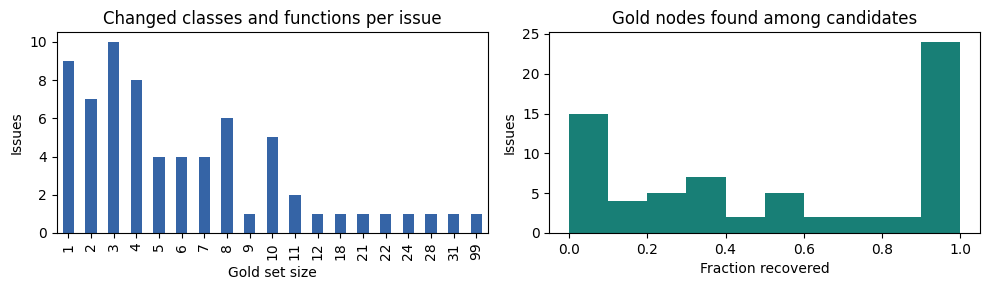

In [12]:
coverage = pd.DataFrame([
    measure_issue_coverage(issue, load_repo, build_issue)
    for issue in issues.to_dict("records")
])
labeled = coverage.loc[coverage.gold_size > 0]
if labeled.empty:
    raise ValueError("No class or function gold labels in this selection. Choose another repository.")

display(summarize_coverage(labeled))
display(labeled.sort_values(["gold_coverage", "issue_id"]).head(8))
plot_coverage(labeled)

## 6. Create train and test datasets and check a GNN forward pass

Use a reproducible chronological 80/20 split **by distinct issue times within each repository**, keeping ties together. This is a starter protocol. The official baseline references filtered split files that were absent from the ModelScope manifest inspected for this notebook. Use the authors' split if you obtain it and want to compare paper numbers.

The PyG dataset builds issue graphs on demand. Preprocessing and the dataset stay on CPU. The smoke test moves the GraphSAGE layer and one batch to the selected device. Later training can use the candidate mask for loss and ranking. Keep all labeled test issues in the evaluation denominator, including cases with no candidates.

### Split issues and build data loaders

In [13]:
def chronological_split(issues):
    split_rows = []
    for repo, rows in issues[issues["gold"].map(bool)].groupby("repo", sort=False):
        times = sorted(rows["time"].unique())
        if len(times) < 2:
            print(f"Skipping split for {repo}: fewer than two distinct labeled issue times.")
            continue
        cutoff = times[min(len(times) - 1, max(1, int(0.8 * len(times))))]
        for row in rows.to_dict("records"):
            split_rows.append({**row, "split": "train" if row["time"] < cutoff else "test"})

    if not split_rows:
        raise ValueError("No temporal split could be created for this repository selection.")
    return pd.DataFrame(split_rows)

def add_validation_split(split_table, val_frac=0.2):
    """Relabel the latest val_frac of distinct train issue times as 'val' (ties stay together)."""
    out = split_table.copy()
    for repo in out["repo"].unique():
        is_train = (out["repo"] == repo) & (out["split"] == "train")
        times = sorted(out.loc[is_train, "time"].unique())
        if len(times) < 2:
            print(f"Skipping validation split for {repo}: fewer than two distinct train times.")
            continue
        cutoff = times[min(len(times) - 1, max(1, int((1 - val_frac) * len(times))))]
        out.loc[is_train & (out["time"] >= cutoff), "split"] = "val"
    return out

class GrepoIssueDataset(torch.utils.data.Dataset):
    def __init__(self, rows, build_issue):
        self.rows = rows.to_dict("records")
        self.build_issue = build_issue

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.build_issue(self.rows[index])

In [14]:
split_table = add_validation_split(chronological_split(issues))
display(split_table.groupby(["repo", "split"]).size().unstack(fill_value=0))

def make_dataset(name):
    return GrepoIssueDataset(split_table[split_table["split"] == name], build_issue)

train_dataset, val_dataset, test_dataset = map(make_dataset, ["train", "val", "test"])

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=2, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=2, shuffle=False)

split,test,train,val
repo,,,
csvkit,13,45,10


In [15]:
counts = split_table["split"].value_counts()
assert counts["test"] == 13 and counts["train"] + counts["val"] == 55, counts

g = train_dataset[0]
print(g.gold_size, g.gold_ids[:5], int(g.y.sum()), "of", g.gold_size, "gold nodes reachable")
assert int(g.y.sum()) <= g.gold_size

3 tensor([2177, 2178, 2281]) 2 of 3 gold nodes reachable


Imports and graph cache

In [16]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv

def cache(ds):
    return [ds[i] for i in range(len(ds))]

train_graphs, val_graphs, test_graphs = map(cache, [train_dataset, val_dataset, test_dataset])

cov_split = labeled.merge(split_table[["repo", "issue_id", "split"]], on=["repo", "issue_id"])
display(cov_split.groupby("split")[["gold_coverage", "any_gold_reachable", "all_gold_reachable"]].mean().round(3))

,gold_coverage,any_gold_reachable,all_gold_reachable
split,,,
test,0.544,0.769,0.308
train,0.495,0.800,0.311
val,0.696,1.000,0.600


Metrics

In [17]:
KS = (1, 5, 10, 20)

def rank_metrics(graph, scores, generator, ks=KS):
    cand = graph.candidate_mask.nonzero(as_tuple=True)[0]
    gold = set(graph.gold_ids.tolist())
    ranked = []
    if cand.numel():
        s = scores[cand].float()
        perm = torch.randperm(cand.numel(), generator=generator)
        order = perm[torch.argsort(s[perm], descending=True, stable=True)]
        ranked = graph.original_node_id[cand[order]].tolist()
    out = {}
    for k in ks:
        hits = len(gold & set(ranked[:k]))
        out[f"hit@{k}"] = float(hits > 0)
        out[f"recall@{k}"] = hits / graph.gold_size
        out[f"all@{k}"] = float(hits == graph.gold_size)
    return out

def evaluate(graphs, score_fn, seed=0):
    gen = torch.Generator().manual_seed(seed)
    rows = [dict(issue_id=g.issue_id, reachable=bool(g.y.any()),
                 **rank_metrics(g, score_fn(g), gen)) for g in graphs]
    return pd.DataFrame(rows)

METRIC_COLS = [f"{m}@{k}" for m in ("hit", "recall", "all") for k in KS]

Reference rank

In [18]:
random_scorer    = lambda g: torch.zeros(g.num_nodes)
seed_scorer = lambda g: g.x[:, 5]

Models

In [19]:
class Ranker(nn.Module):
    def __init__(self, in_dim, kind="sage", hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.kind, self.dropout = kind, dropout
        dims = [in_dim] + [hidden] * layers
        make = {"mlp": nn.Linear, "sage": SAGEConv, "gat": GATConv}[kind]
        self.layers = nn.ModuleList(make(a, b) for a, b in zip(dims, dims[1:]))
        self.out = nn.Linear(hidden, 1)

    def forward(self, x, edge_index):
        for layer in self.layers:
            x = layer(x) if self.kind == "mlp" else layer(x, edge_index)
            x = F.dropout(F.relu(x), self.dropout, self.training)
        return self.out(x).squeeze(-1)

@torch.no_grad()
def model_scorer(model):
    model.eval()
    return lambda g: model(g.x.to(device), g.edge_index.to(device)).cpu()

Training

In [20]:
def pos_weight(graphs):
    cand = sum(int(g.candidate_mask.sum()) for g in graphs)
    pos = sum(int(g.y[g.candidate_mask].sum()) for g in graphs)
    return torch.tensor((cand - pos) / max(pos, 1))

def train_model(kind, train_g, val_g, seed, epochs=100, lr=1e-3, hidden=64,
                layers=2, patience=20, batch_size=4):
    torch.manual_seed(seed)
    model = Ranker(train_g[0].num_node_features, kind, hidden, layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight(train_g).to(device))
    loader = DataLoader(train_g, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    best, best_state, bad = -1.0, None, 0
    for epoch in range(epochs):
        model.train()
        for batch in loader:
            batch = batch.to(device)
            opt.zero_grad()
            logits = model(batch.x, batch.edge_index)
            m = batch.candidate_mask
            F_loss = loss_fn(logits[m], batch.y[m])
            F_loss.backward()
            opt.step()
        val = evaluate(val_g, model_scorer(model), seed=0)["recall@10"].mean()
        if val > best:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best

In [21]:
def with_edge_mode(graph, edge_mode, seed=None):
    """Return a copy of the graph (or list of graphs) with edges kept, removed, or shuffled."""
    if isinstance(graph, list):
        return [with_edge_mode(g, edge_mode, seed=seed) for g in graph]

    g = graph.clone()
    if edge_mode == "real":
        return g
    elif edge_mode == "none":
        g.edge_index = torch.empty((2, 0), dtype=torch.long)
        g.edge_attr = torch.empty((0,), dtype=torch.long)
    elif edge_mode == "shuffled":
        if g.edge_index.numel() > 0:
            if seed is not None:
                torch.manual_seed(seed)
            num_edges = g.edge_index.size(1)
            # Shuffling only targets to preserve degrees, or random permutation of edge indices
            perm = torch.randperm(num_edges)
            g.edge_index = g.edge_index[:, perm]
            g.edge_attr = g.edge_attr[perm]
    return g

Results

In [22]:
def run(kind, edge_mode="real", seeds=range(5), **kw):
    runs = []
    for s in seeds:
        tr, va, te = (with_edge_mode(g, edge_mode, seed=s)
                      for g in (train_graphs, val_graphs, test_graphs))
        model, _ = train_model(kind, tr, va, seed=s, **kw)
        runs.append(evaluate(te, model_scorer(model), seed=s))
    return runs

def results_table(results, subset="all"):
    rows = {}
    for name, runs in results.items():
        per_seed = pd.DataFrame([(r if subset == "all" else r[r.reachable])[METRIC_COLS].mean()
                                 for r in runs])
        rows[name] = per_seed.mean().round(3).astype(str) + " ± " + per_seed.std().round(3).astype(str)
    return pd.DataFrame(rows).T

results = {
    "random":     [evaluate(test_graphs, random_scorer, seed=s) for s in range(3)],
    "seed-first": [evaluate(test_graphs, seed_scorer, seed=s) for s in range(3)],
    "MLP":        run("mlp", seeds=range(3)),
    "GraphSAGE":  run("sage", seeds=range(3)),
}
display(results_table(results, "all"))
display(results_table(results, "reachable"))

,hit@1,hit@5,hit@10,hit@20,recall@1,recall@5,recall@10,recall@20,all@1,all@5,all@10,all@20
random,0.077 ± 0.077,0.256 ± 0.118,0.359 ± 0.044,0.436 ± 0.044,0.007 ± 0.009,0.039 ± 0.022,0.08 ± 0.032,0.151 ± 0.024,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.026 ± 0.044
seed-first,0.051 ± 0.044,0.308 ± 0.077,0.462 ± 0.0,0.538 ± 0.0,0.012 ± 0.013,0.077 ± 0.023,0.118 ± 0.008,0.183 ± 0.018,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
MLP,0.154 ± 0.077,0.231 ± 0.077,0.231 ± 0.077,0.641 ± 0.044,0.021 ± 0.02,0.054 ± 0.039,0.068 ± 0.039,0.267 ± 0.013,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.077 ± 0.0
GraphSAGE,0.154 ± 0.0,0.359 ± 0.044,0.538 ± 0.077,0.769 ± 0.0,0.014 ± 0.0,0.135 ± 0.023,0.228 ± 0.012,0.42 ± 0.019,0.0 ± 0.0,0.051 ± 0.044,0.051 ± 0.044,0.205 ± 0.044


,hit@1,hit@5,hit@10,hit@20,recall@1,recall@5,recall@10,recall@20,all@1,all@5,all@10,all@20
random,0.1 ± 0.1,0.333 ± 0.153,0.467 ± 0.058,0.567 ± 0.058,0.009 ± 0.011,0.05 ± 0.029,0.104 ± 0.042,0.197 ± 0.031,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.033 ± 0.058
seed-first,0.067 ± 0.058,0.4 ± 0.1,0.6 ± 0.0,0.7 ± 0.0,0.016 ± 0.017,0.1 ± 0.03,0.154 ± 0.01,0.238 ± 0.024,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
MLP,0.2 ± 0.1,0.3 ± 0.1,0.3 ± 0.1,0.833 ± 0.058,0.027 ± 0.025,0.07 ± 0.051,0.088 ± 0.051,0.348 ± 0.017,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.1 ± 0.0
GraphSAGE,0.2 ± 0.0,0.467 ± 0.058,0.7 ± 0.1,1.0 ± 0.0,0.019 ± 0.0,0.175 ± 0.03,0.297 ± 0.016,0.546 ± 0.025,0.0 ± 0.0,0.067 ± 0.058,0.067 ± 0.058,0.267 ± 0.058


## Project Milestone 1



| Deliverable | Completion criterion |
|---|---|
| GNN-ready dataset | Document the source and regenerate issue graphs, node features, labels, and splits with the download and preprocessing notebook. |
| Notebook 1 · Dataset exploration | Show sample issues, graph sizes and relation counts, change-set sizes, and candidate coverage. |
| Notebook 2 · Train and evaluate a GNN | Train GraphSAGE or GAT for class and function localization. Compare with a feature-only MLP on the same candidate nodes, features, and splits. Report Hit@K, Recall@K, and the fraction of issues whose entire gold set appears in the top K. |
| Analysis · Why GREPO hit rates are low | Measure candidate coverage before ranking. Then measure ranking misses on issues where at least one gold node was reachable. Compare with the paper only under a matching evaluation protocol. |
| Analysis · Does graph structure help? | Compare real edges with no edges and a shuffled-edge control. Keep candidate generation fixed so the result isolates message passing. Separately compare candidate coverage before and after graph expansion. |
| Future direction | Use the results to decide whether to improve retrieval, revise graph relations, or try a set decoder. Document the representative successes and failures behind that choice. |

**Public repo contents** · README, both notebooks, reproducible environment setup, and a short results write-up.